# 3.8 Despliegue e interfaz

> Borrador de la sección 3.8 (Gerónimo). Se integra en `model_development.ipynb`. Cada decisión sigue el formato **Decisión / Alternativas / Por qué / Evidencia**.

**Qué pide el enunciado:** el modelo debe desplegarse con una interfaz que una persona sin conocimientos técnicos pueda usar.

**Qué hicimos:** una app de Streamlit en la que se pega el número de un contrato de SECOP II. Consulta datos.gov.co, arma las mismas variables del entrenamiento y muestra el nivel de riesgo, el percentil y los factores que más pesan, con avisos.

**URL pública:** `[PENDIENTE: se completa al publicar en Streamlit Community Cloud]`

Datos: [datos.gov.co](https://www.datos.gov.co), Colombia Compra Eficiente (SECOP II), licencia CC BY-SA 4.0.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", message="IProgress not found")     # aviso de tqdm al importar shap sin ipywidgets

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import api_secop as A, config, explicacion as E, features as F, modelo_io

RUTA_BASE = config.BASE_V1
print("Base local disponible:", RUTA_BASE.exists())

Base local disponible: True


## Qué ingresa el usuario

**Decisión:** el usuario solo pega el número del contrato (`CO1.PCCNTR.n`) o el enlace de su página. La app hace el resto.

**Alternativas consideradas:**
- Un formulario con las variables del contrato.
- Pegar la referencia del contrato.
- Pegar el número del proceso.

**Por qué:**
- Un formulario obliga a conocer variables como el código UNSPSC o los conteos de proponentes. Quien vigila un contrato no las tiene a la mano.
- Según los metadatos del dataset, `id_contrato` es "el identificador del contrato firmado, generado por la plataforma". La referencia la genera cada entidad y no es única, y `CO1.BDOS.n` identifica el proceso, no el contrato. Si el usuario pega un número de proceso, la app se lo explica.

**Evidencia:** la tabla siguiente sale del código de la app y del entrenamiento, no está escrita a mano.

In [2]:
familias = F.tabla_features().groupby("familia")["feature"].count()
tabla_usuario = pd.DataFrame({
    "1. Lo que pega el usuario": ["El número del contrato (CO1.PCCNTR.n) o el enlace de su página de SECOP II"],
    "2. Lo que consulta la app": [
        f"Contratos (jbjy-vk9h): {len(A.COLS_CONTRATO_API)} columnas. "
        f"Procesos (p6dx-8zbt): {len(A.COLS_PROCESO_API)} columnas. Una petición por segundo."],
    "3. Las variables que construye": [
        f"{len(F.FEATURES)} features, las mismas del entrenamiento y todas disponibles al firmar: "
        + ", ".join(f"{k} ({v})" for k, v in familias.items())],
    "4. Lo que descarta y por qué": [
        f"{len(F.COLUMNAS_FUGA)} columnas de fuga (estado, fecha de fin, valor, pagos, liquidación...): no se piden "
        f"aunque la API las devuelva actualizadas. {len(config.PII)} columnas con datos personales: nunca se piden. "
        f"Identidad del proveedor: excluida por privacidad (Ley 1581 de 2012)."],
}).T
tabla_usuario.columns = [""]
pd.set_option("display.max_colwidth", None)
display(tabla_usuario)

,
1. Lo que pega el usuario,El número del contrato (CO1.PCCNTR.n) o el enlace de su página de SECOP II
2. Lo que consulta la app,Contratos (jbjy-vk9h): 27 columnas. Procesos (p6dx-8zbt): 17 columnas. Una petición por segundo.
3. Las variables que construye,"39 features, las mismas del entrenamiento y todas disponibles al firmar: Calendario (4), Contrato (17), Entidad (5), Geografia (2), Proceso (12)"
4. Lo que descarta y por qué,"66 columnas de fuga (estado, fecha de fin, valor, pagos, liquidación...): no se piden aunque la API las devuelva actualizadas. 29 columnas con datos personales: nunca se piden. Identidad del proveedor: excluida por privacidad (Ley 1581 de 2012)."


In [3]:
# Lo que se le pide a la API: solo columnas de entrada. Si alguna fuera de fuga o de datos personales, esto falla.
pedidas = set(A.COLS_CONTRATO_API) | set(A.COLS_PROCESO_API)
assert not pedidas & F.COLUMNAS_FUGA, "se estaria pidiendo una columna de fuga"
assert not pedidas & config.PII, "se estaria pidiendo una columna con datos personales"
print(f"Columnas pedidas a la API: {len(pedidas)} | de fuga: {len(pedidas & F.COLUMNAS_FUGA)} | personales: {len(pedidas & config.PII)}")

Columnas pedidas a la API: 44 | de fuga: 0 | personales: 0


## Cómo fluye una consulta

```
Usuario ──número o enlace──> app (Streamlit) ──> src/api_secop.py: extrae CO1.PCCNTR.n
                                                       │
                datos.gov.co: Contratos + Procesos (1 petición/s, solo columnas de entrada)
                                                       │
        elegir_proceso → unir_contrato_proceso → construir_features   (las mismas funciones del entrenamiento)
                                                       │
                   modelo guardado (models/) → puntaje → nivel de riesgo y percentil
                                                       │
            SHAP → 5 factores en lenguaje claro  +  avisos  +  aclaración de alcance
```

**Decisión:** la app no tiene su propia copia de la lógica de variables: llama a `construir_features`, la misma función que usó el entrenamiento.

**Por qué:** si la app y el entrenamiento calcularan las variables por separado, el modelo recibiría en producción datos distintos de los que vio al entrenar, y nada fallaría a la vista. **Evidencia:** la prueba de paridad de más abajo.

## Qué muestra la app

**Decisión:** mostrar el **nivel de riesgo** (bajo, medio, alto) y el **percentil**, no la probabilidad cruda.

**Alternativas consideradas:** mostrar la probabilidad (por ejemplo, "23 %").

**Por qué:** con la deriva de los datos (ver 3.9) la probabilidad queda descalibrada, y una cifra exacta sugiere una precisión que el modelo no tiene. El percentil dice algo que sí se sostiene: dónde queda este contrato frente a los de referencia. Para quien prioriza qué vigilar primero, el orden importa más que el valor.

**Evidencia:** tres contratos reales calculados con el mismo código de la app (desde la copia local, sin red):

In [4]:
EJEMPLOS = {"alto": "CO1.PCCNTR.6169204", "medio": "CO1.PCCNTR.7136864", "bajo": "CO1.PCCNTR.6242834"}
v1 = config.MODELS / "modelo_prorroga_v1.joblib"
ruta_modelo = v1 if v1.exists() else config.MODELS / "modelo_prorroga_dummy.joblib"
pipeline, meta = modelo_io.cargar_modelo(ruta_modelo)
explicador = E.Explicador(pipeline)
print("Modelo:", meta["version"], "|", ruta_modelo.name)

if RUTA_BASE.exists():
    filas, explicaciones = [], {}
    for etiqueta, idc in EJEMPLOS.items():
        c = A.consulta_desde_respaldo(RUTA_BASE, idc)
        e = explicador.explicar(c.features, c.contrato)
        nivel, pct = E.nivel_y_percentil(e.puntaje, meta)
        explicaciones[etiqueta] = e
        top = e.aportes.iloc[0]
        filas.append({"ejemplo": etiqueta, "entidad": c.contrato["nombre_entidad"], "firma": c.contrato["fecha_de_firma"],
                      "nivel": nivel, "percentil": round(pct), "factor principal": f"{top['nombre']}: {top['valor']}",
                      "avisos": ", ".join(c.avisos) or "-"})
    display(pd.DataFrame(filas))
else:
    print("No hay base local: este ejemplo se ejecuta con data/processed/v1_A/base_contratos.parquet")

Modelo: dummy-0 | modelo_prorroga_dummy.joblib


,ejemplo,entidad,firma,nivel,percentil,factor principal,avisos
0,alto,DEFENSORÍA DEL PUEBLO,2024-04-05,alto,100,"Precio base del proceso: $ 960,4 millones",-
1,medio,MUNICIPIO DE ITAGUI,2025-01-01,medio,87,"Precio base del proceso: $ 1,9 mil millones",-
2,bajo,DEPARTAMENTO DE SANTANDER,2024-04-24,bajo,0,Días entre la firma y el inicio: sin dato,-


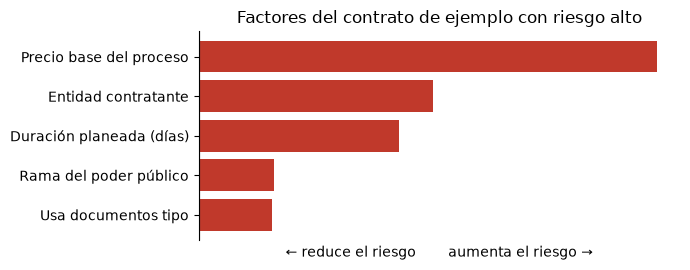

In [5]:
if RUTA_BASE.exists():
    e = explicaciones["alto"]
    datos = e.aportes.head(5).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(datos["nombre"], datos["aporte"], color=["#c0392b" if a > 0 else "#2e86c1" for a in datos["aporte"]])
    ax.axvline(0, color="#555", linewidth=0.8)
    ax.set_xticks([])
    ax.set_xlabel("← reduce el riesgo        aumenta el riesgo →")
    ax.set_title("Factores del contrato de ejemplo con riesgo alto")
    for lado in ("top", "right", "bottom"):
        ax.spines[lado].set_visible(False)
    plt.tight_layout()
    plt.show()

**Interpretación:** el gráfico muestra la dirección de cada factor, no su valor, porque los valores están en log-odds y no le dicen nada a un usuario sin conocimientos técnicos. Cada factor se lee frente a un contrato típico: "sube" o "baja" el riesgo respecto al promedio del modelo.

## Explicación con SHAP: se verifica que sea correcta antes de mostrarla

**Decisión:** explicar con `TreeExplainer` sobre el estimador final y **verificar la aditividad en cada consulta**: la suma de los valores SHAP más el valor base debe reproducir la salida del modelo (error máximo menor que 1e-3). Si no se cumple, la app oculta los factores y muestra solo el nivel.

**Alternativas consideradas:**
- Un explicador genérico sobre `predict_proba` (más lento).
- No mostrar factores.

**Por qué:** `TreeExplainer` sobre un `HistGradientBoostingClassifier` con categorías nativas no lanza error pero da atribuciones incorrectas (error de hasta 13,6 log-odds en una prueba sintética). Una explicación equivocada que parece correcta es peor que ninguna. Por eso el explicador se niega a crearse si el modelo usa categorías nativas.

**Evidencia:** aditividad sobre 300 contratos de 2024 con el modelo cargado:

In [6]:
if RUTA_BASE.exists():
    base24 = pd.read_parquet(RUTA_BASE, columns=A.COLS_RESPALDO + ["anio_firma"], filters=[("anio_firma", "==", 2024)])
    muestra = base24.sample(300, random_state=config.SEED)
    errores = []
    for i in range(len(muestra)):
        fila = muestra.iloc[[i]]
        errores.append(explicador.explicar(F.construir_features(fila)).error_aditividad)
    errores = np.array(errores)
    display(pd.DataFrame({"contratos": [len(errores)], "error máximo": [errores.max()], "error mediano": [np.median(errores)],
                          "criterio": [E.TOLERANCIA_ADITIVIDAD], "cumple": [bool((errores < E.TOLERANCIA_ADITIVIDAD).all())]}))

,contratos,error máximo,error mediano,criterio,cumple
0,300,8.881784e-15,8.881784e-16,0.001,True


**Interpretación:** el error es del orden de 1e-15, trece órdenes de magnitud por debajo del criterio. Con el modelo final (v1) se repite esta misma verificación; si el modelo usa categorías nativas, el equipo decide entre un explicador genérico o entrenar sin ellas (ver 3.5).

## La app y el entrenamiento ven los mismos datos

**Evidencia:** prueba de paridad (`python -m src.paridad_api`). Toma 21 contratos de la base (3 por año de firma, 2019-2025), los pide a datos.gov.co y compara, variable por variable, lo que arma la app contra lo que tiene la base de entrenamiento.

**Por qué importa:** la API devuelve las fechas con hora y la base las tiene truncadas al día. Si la app no las truncara, `dias_firma_a_inicio` saldría corrido un día. `construir_features` las trunca, y la prueba lo confirma:

In [7]:
paridad = RAIZ / "resultados" / "paridad_api_base.md"
display(Markdown(paridad.read_text(encoding="utf-8")) if paridad.exists() else "Falta resultados/paridad_api_base.md")

# Paridad API frente a base

- Fecha de la prueba: 2026-10-26 11:36
- Contratos comparados: 21 (3 por anio de firma, 2019-2025, semilla 42)
- Celdas comparadas (contratos x 39 features): 819
- Celdas distintas: 0
- Peticiones a datos.gov.co: 2

Compara `construir_features` aplicada a lo que devuelve la API contra la aplicada a las filas de la base v1.


**Interpretación:** 819 celdas comparadas y ninguna diferencia, y el puntaje del modelo es idéntico con los datos de la API que con los de la base. La consulta en vivo no introduce una diferencia entre entrenamiento y uso.

## Cómo se ve

Pantallas de la app con un contrato real (modelo de prueba):

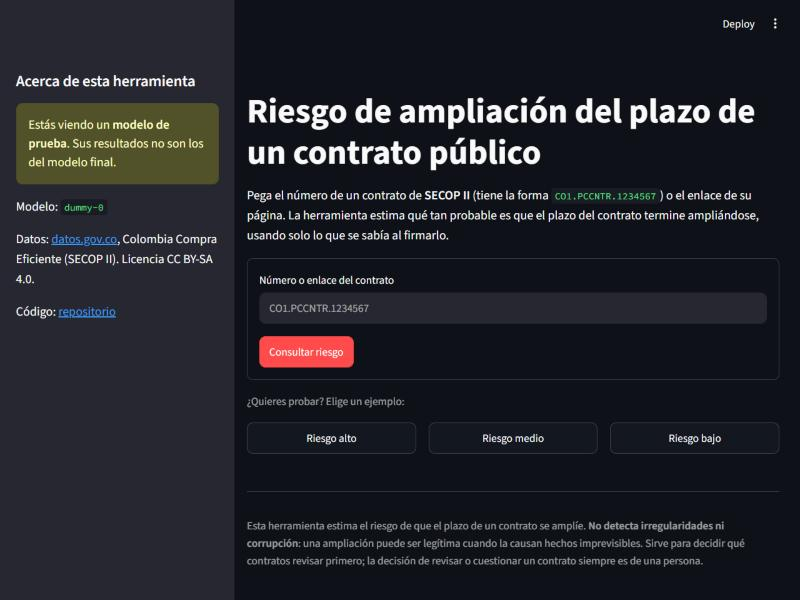

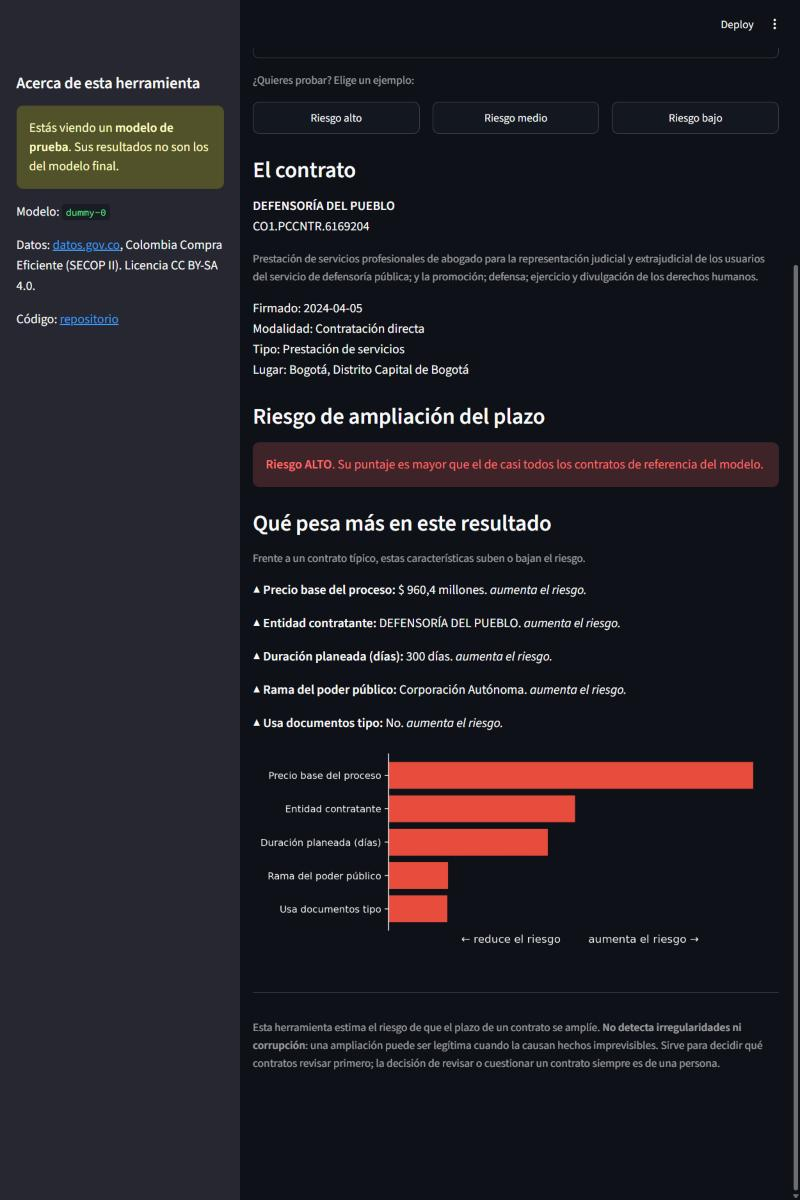

In [8]:
for nombre in ("app_inicio.jpg", "app_resultado.jpg"):
    ruta = RAIZ / "docs" / "img" / nombre
    if ruta.exists():
        display(Image(filename=str(ruta), width=560))

## Dónde se publica y qué se midió

**Decisión:** Streamlit Community Cloud, con el modelo y la app en el mismo repositorio público.

**Alternativas consideradas:** Hugging Face Spaces y Render.

**Por qué:** despliega desde el mismo repositorio y se actualiza en cada `push`; la RAM de la app cabe con holgura en el mínimo de la plataforma. Hugging Face exige un repositorio aparte y Render gratuito ofrece unos 512 MB, demasiado justo para `shap` y `scikit-learn` [SUPUESTO, no verificado].

**Evidencia:**

| Dato | Valor |
|---|---|
| RAM de la app desplegada (modelo, explicador y 3 consultas) | 290 MB |
| Mínimo de RAM por app en Community Cloud | 690 MB (máximo 2,7 GB), aproximado a febrero de 2024 |
| Apps sin tráfico | se duermen a las 12 horas |
| Si se cargara la base completa como respaldo | 1.019 MB: por eso el respaldo busca el contrato por lotes y no carga la base |

El detalle y los pasos están en `docs/DESPLIEGUE.md`.

## Limitaciones

- Hoy la app usa el **modelo de prueba** (dummy); se cambia al modelo v1 cuando Jose lo entregue, y sus cifras no se citan.
- La explicación dice qué pesó en el puntaje del modelo, **no** por qué se amplía un contrato: no es una relación causal.
- En el contrato de menor riesgo del ejemplo, el factor dominante es que **no hay fecha de inicio registrada**: el modelo trata el dato faltante como señal protectora. Es un hallazgo para la ablación de `dias_firma_a_inicio` (3.6).
- El aviso de "entidad sin historial" se activa cuando el modelo guarde la lista de entidades que vio al entrenar [NO EVALUADO con el dummy].
- La app estima riesgo de **ampliación del plazo**, no detecta irregularidades ni corrupción, y es una herramienta de priorización: la decisión de revisar un contrato es de una persona.